<a href="https://colab.research.google.com/github/jberisso/BA305-A1---hotel-bookings/blob/main/00_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import CountVectorizer
from tqdm import tqdm

In [3]:
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv"
df = pd.read_csv(url)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


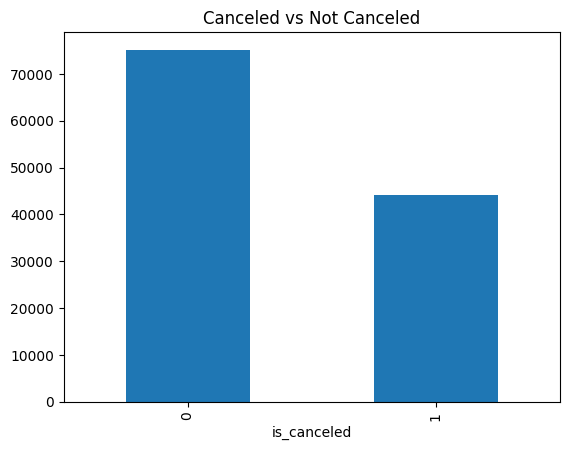

In [4]:
df['is_canceled'].value_counts().plot(kind='bar')
plt.title('Canceled vs Not Canceled')
plt.show()

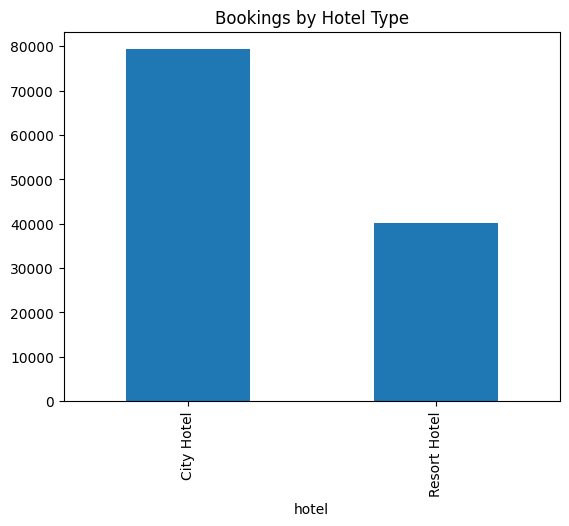

In [5]:
df['hotel'].value_counts().plot(kind='bar')
plt.title('Bookings by Hotel Type')
plt.show()

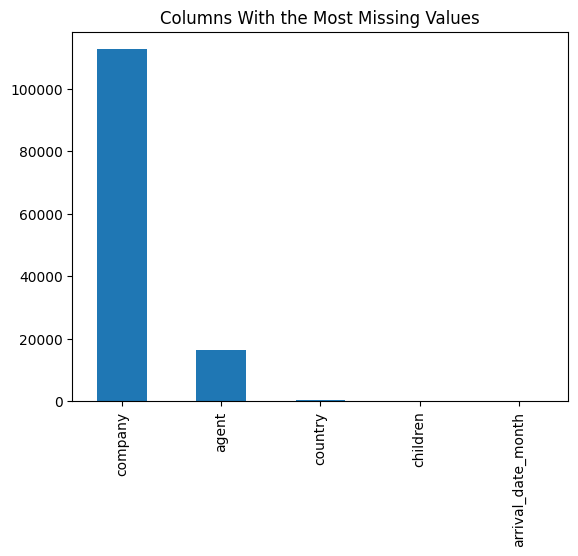

In [6]:
df.isna().sum().sort_values(ascending=False).head(5).plot(kind='bar')
plt.title('Columns With the Most Missing Values')
plt.show()

In [7]:
df.groupby('deposit_type')['is_canceled'].mean()

,is_canceled
deposit_type,
No Deposit,0.283770
Non Refund,0.993624
Refundable,0.222222


In [8]:
df['deposit_type'].value_counts()

,count
deposit_type,
No Deposit,104641
Non Refund,14587
Refundable,162


In [9]:
df[df['deposit_type'] == 'Non Refund']['distribution_channel'].value_counts()

,count
distribution_channel,
TA/TO,13651
Corporate,538
Direct,398


rows: 104803 | base cancellation rate: 28.4%

                 n  lead_min  lead_max  cancel_rate
lead_decile                                        
0            11842         0         2          7.9
1             9889         3         9         12.9
2             9779        10        20         24.3
3            10513        21        36         30.1
4            10813        37        57         33.4
5            10123        58        83         32.4
6            10421        84       117         34.2
7            10557       118       162         34.5
8            10435       163       223         35.4
9            10431       224       737         40.0


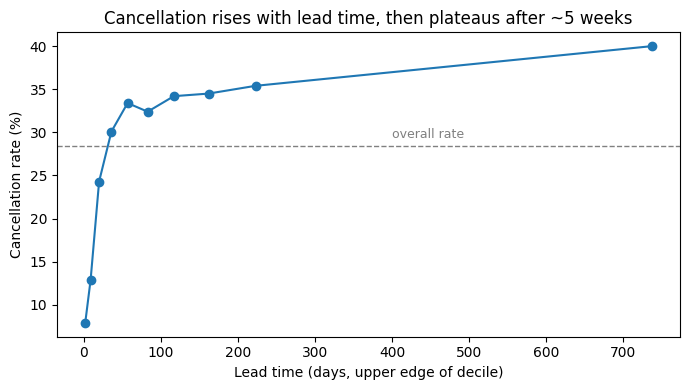

In [10]:
#Checking the intuition that longer lead times mean more cancellations
# Non Refund bookings are excluded: 81 of 87 agents cancel at exactly 100% on them,
# while the same agents cancel at 15-39% on their No Deposit bookings. Treating those
clean = df[df['deposit_type'] != 'Non Refund'].copy()
print('rows:', len(clean), '| base cancellation rate: %.1f%%' % (clean['is_canceled'].mean()*100))

clean['lead_decile'] = pd.qcut(clean['lead_time'], 10, labels=False, duplicates='drop')
trend = clean.groupby('lead_decile').agg(
    n=('is_canceled', 'size'),
    lead_min=('lead_time', 'min'),
    lead_max=('lead_time', 'max'),
    cancel_rate=('is_canceled', 'mean'))
trend['cancel_rate'] = (trend['cancel_rate']*100).round(1)
print()
print(trend)

ax = trend.plot(x='lead_max', y='cancel_rate', marker='o', legend=False, figsize=(7,4))
ax.set_xlabel('Lead time (days, upper edge of decile)')
ax.set_ylabel('Cancellation rate (%)')
ax.set_title('Cancellation rises with lead time, then plateaus after ~5 weeks')
ax.axhline(clean['is_canceled'].mean()*100, ls='--', c='grey', lw=1)
ax.text(400, clean['is_canceled'].mean()*100+1, 'overall rate', color='grey', fontsize=9)
plt.tight_layout(); plt.show()

In [11]:
print(df.columns.tolist())

['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']


In [12]:
print("Number of unique countries:", df['country'].nunique())
country_counts = df['country'].value_counts()
print(country_counts.head(15))
 # ^^^ Top 15 countries by number of bookings

Number of unique countries: 177
country
PRT    48590
GBR    12129
FRA    10415
ESP     8568
DEU     7287
ITA     3766
IRL     3375
BEL     2342
BRA     2224
NLD     2104
USA     2097
CHE     1730
CN      1279
AUT     1263
SWE     1024
Name: count, dtype: int64


In [13]:
print("Countries with fewer than 50 bookings:", (country_counts < 50).sum())
print("Total number of countries:", len(country_counts))
# ^^^ How many countries have fewer than 50 bookings out of the total? (We want to group them together)

Countries with fewer than 50 bookings: 120
Total number of countries: 177


In [14]:
top_countries = df['country'].value_counts().head(8).index
df['country_grouped'] = df['country'].where(df['country'].isin(top_countries), 'Other')
# ^^^ We grouped rare booked countries into "Other. From the check above about 120 of the 177 countries have fewer than 50 bookings each, while a handful account for most of the data.
# We want to keep the top 8 coutries separate and lump everything else into "Other" to keeps enough bookings per group to actually compare.

/tmp/ipykernel_368/1563751373.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cancel_rates = df.groupby(['country_grouped', 'lead_time_bucket'])['is_canceled'].mean().unstack()


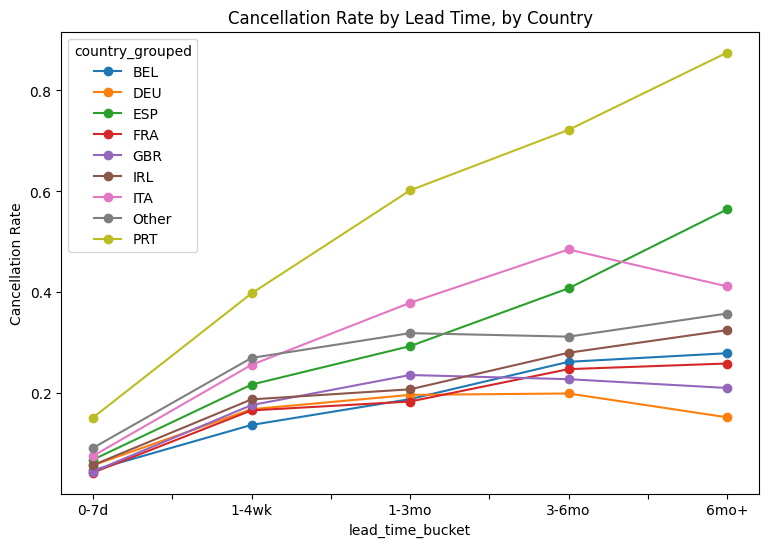

In [15]:
df['lead_time_bucket'] = pd.cut(df['lead_time'], bins=[0, 7, 30, 90, 180, 1000],
                                  labels=['0-7d', '1-4wk', '1-3mo', '3-6mo', '6mo+'])
cancel_rates = df.groupby(['country_grouped', 'lead_time_bucket'])['is_canceled'].mean().unstack()
cancel_rates.T.plot(marker='o', figsize=(9, 6))
plt.ylabel('Cancellation Rate')
plt.title('Cancellation Rate by Lead Time, by Country')
plt.show()
# ^^^ We made a chart of cancellation rate by lead time and had it split by country
# We want to find if the relationship between lead time (how far in advance someone booked) and cancellation look different depending on the guest's country, or does it look roughly
# the same everywhere? We split lead time into buckets since a  day count would make the chart too noisy and messy to read.

In [16]:
# From the chart we can see that Portugal (PRT) is a massive outlier. It starts around 15% cancellation for last-minute bookings and climbs to nearly 90% for bookings made 6+ months out
# Most other countries cluster together in a much lower band (BEL, DEU, FRA, GBR, IRL), rising gently from near 0% up to roughly 15-30% at the far end.
# We can also see that ESP and ITA sit in between, climbing to 40-55% which is clearly above the low cluster but nowhere near PRT’s extreme.
# This directly answers 'yes' to our question of if the lead-time to cancellation relationship clearly does differ by country.

In [17]:
group_counts = df.groupby(['country_grouped', 'lead_time_bucket']).size().unstack()
print(group_counts)
# ^^^ Just to make sure, we wanted to check how many bookings are actually behind each line on the chart.
# A cancellation RATE alone can be misleading if the group it's based on is tiny. This shows the actual COUNT behind every country/lead-time combination, so we can tell which parts of the
# chart are backed by solid sample sizes and which parts might just be noise from a small group.

lead_time_bucket  0-7d  1-4wk  1-3mo  3-6mo   6mo+
country_grouped                                   
BEL                192    322    692    676    398
DEU                442    840   1768   1713   2365
ESP               1476   2155   2745   1278    491
FRA                972   2030   3239   2458   1327
GBR                705   1682   2945   3131   3405
IRL                158    411    873   1072    813
ITA                319    684   1040   1077    525
Other             2471   4381   6297   5395   3202
PRT               6666   6455   9954   9639  12166


/tmp/ipykernel_368/3092966481.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_counts = df.groupby(['country_grouped', 'lead_time_bucket']).size().unstack()


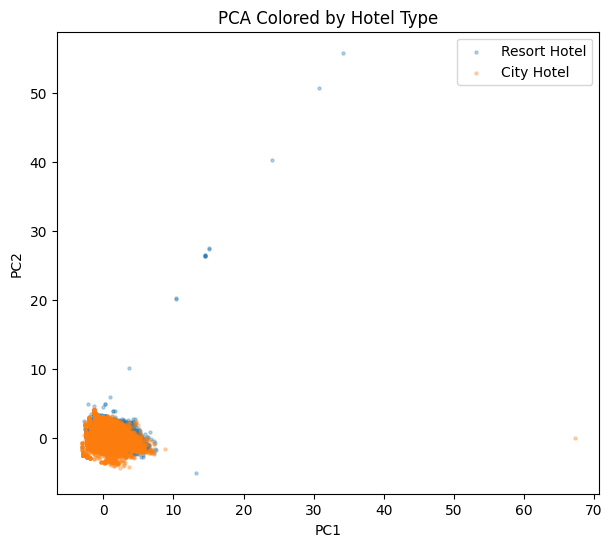

Explained variance ratio: [0.30273916 0.22357076]


In [18]:
features = ['lead_time', 'adr', 'adults', 'children', 'total_of_special_requests']
pca_data = df[features].fillna(0)
# ^^^ We want to conduct PCA to compress multiple booking features into 2 dimensions to see if city hotel and resort hotel bookings form visually distinct groups,
# which is what our descriptive question is asking.

scaled = StandardScaler().fit_transform(pca_data)

pca = PCA(n_components=2)
pcs = pca.fit_transform(scaled)
# ^^^ We reduced down to 2 principal components so we can plot it instead of 5.

plt.figure(figsize=(7, 6))
for h in df['hotel'].unique():
    mask = df['hotel'] == h
    plt.scatter(pcs[mask, 0], pcs[mask, 1], label=h, alpha=0.3, s=5)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.legend()
plt.title('PCA Colored by Hotel Type')
plt.show()
# ^^^ We used colored points by hotel type AFTER the fact, since hotel type was not used to build the components, only to visualize the result.

print("Explained variance ratio:", pca.explained_variance_ratio_)

In [19]:
# We run k-NN below to answer if lead time, country, market segment, adults, and customer_type predict whether a booking is canceled?
# Since k-NN requires choosing k (number of neighbors) and there's no way to know the best value ahead of time, we tested k = 1 to 19 instead of guessing one value.

In [20]:
# Separate the predictors (X) from the target we want to predict (y).
knn_df = df[['is_canceled', 'lead_time', 'adults', 'country_grouped', 'market_segment', 'customer_type']].copy()

In [21]:
for col in ['country_grouped', 'market_segment', 'customer_type']:
    knn_df[col] = knn_df[col].astype('category')
knn_df = pd.get_dummies(knn_df, prefix_sep='_', drop_first=False)

In [22]:
X = knn_df.drop(columns=['is_canceled'])
y = knn_df['is_canceled']

In [23]:
# Split into training (60%) and test (40%) sets, keeping the share of 1's equal in both.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=2, stratify=y)
print('Training set:', X_train.shape, 'Testing set:', X_test.shape)

Training set: (71634, 23) Testing set: (47756, 23)


In [24]:
scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [25]:
# Fit a model for every k from 1 to 50 and record its test accuracy.
results = []
for k in tqdm(range(1, 20)):
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_train_scaled, y_train)
    results.append({
        'k': k,
        'accuracy': accuracy_score(y_test, knn.predict(X_test_scaled))
    })

# Collect the results in a table and show the first few rows.
results_df = pd.DataFrame(results)
results_df.head()

100%|██████████| 19/19 [07:09<00:00, 22.59s/it]


,k,accuracy
0,1,0.746147
1,2,0.773683
2,3,0.771861
3,4,0.782394
4,5,0.779253


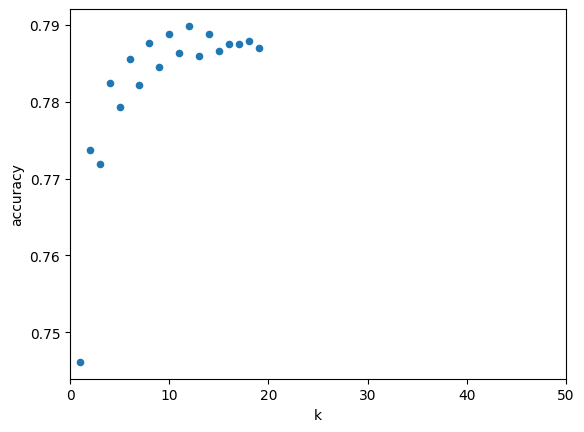

In [26]:
# Plot accuracy against k.
results_df.plot.scatter(x='k', y='accuracy', xlim=[0, 50]);

In [27]:
# Find the highest accuracy and the k that produced it.
best_row = results_df['accuracy'].idxmax()
print('Max accuracy =', results_df.loc[best_row, 'accuracy'], '|', 'Best k =', results_df.loc[best_row, 'k'])

Max accuracy = 0.7898483960130664 | Best k = 12


In [28]:
# Accuracy starts at 0.746 (k = 1), rises, then levels off around 0.78-0.79 by roughly k = 10-15. That plateau shows the result isn't just
# luck from picking one k as performance stabilizes once k is large enough.

In [29]:
# We ran a leakage check between assigned vs reserved room type, and reservation_status
# 1) How often does the assigned room differ from the reserved one, by cancellation status?
room_changed = df['assigned_room_type'] != df['reserved_room_type']
leak = pd.DataFrame({
    'bookings': df.groupby('is_canceled').size(),
    'room changed (%)': (room_changed.groupby(df['is_canceled']).mean() * 100).round(1),
})
leak.index = ['not canceled (0)', 'canceled (1)']
print(leak)

# 2) Cancellation rate when the room was changed vs kept
print('\nCancellation rate (%) by room assignment:')
print((df.groupby(room_changed)['is_canceled'].mean() * 100).round(1)
        .rename(index={False: 'same room as reserved', True: 'room changed'}))

# 3) reservation_status against the target
print('\nreservation_status vs is_canceled:')
print(pd.crosstab(df['reservation_status'], df['is_canceled']))

                  bookings  room changed (%)
not canceled (0)     75166              18.8
canceled (1)         44224               1.8

Cancellation rate (%) by room assignment:
same room as reserved    41.6
room changed              5.4
Name: is_canceled, dtype: float64

reservation_status vs is_canceled:
is_canceled             0      1
reservation_status              
Canceled                0  43017
Check-Out           75166      0
No-Show                 0   1207


In [30]:
# Since our aim is to predict the variable is_canceled, we should remove the variable reservation_status from our model entirely
# because it reveals the final outcome, giving the model information that it wouldn't actually have when making a real
# prediction. We also need to then perform more investigation on varaiables like assigned_room_type to see if they are
# updated before or after our intended prediction time.

**Response to TA feedback on Portugal.**

We realized that we must look deeper into portugal's outlier status in order to approach how or whether or not we can use Country as a predictor for our Predictive Question. i.e We strive to find a "real world" practical reason. The Below block of code is our hypothesis that Portugal is actually the default place holder when making a booking when the user does not provide one. Which explain it's high usage rate.

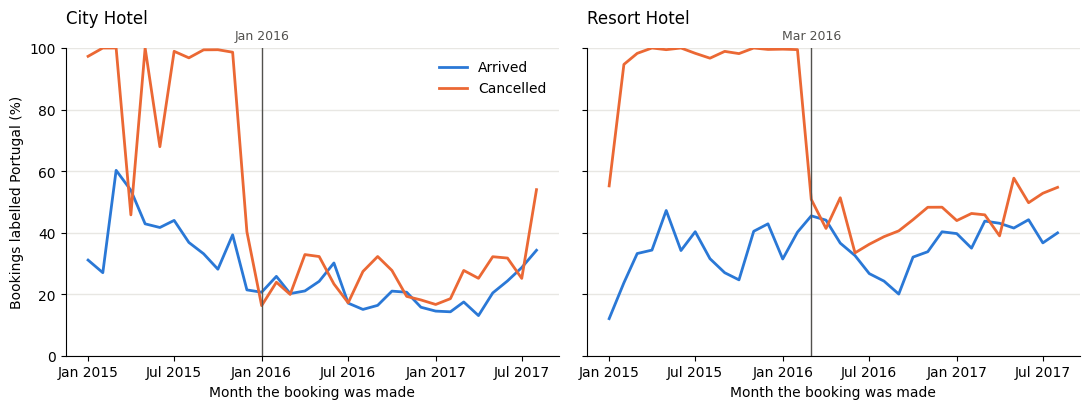

Cancellation rate (%), Non Refund excluded:
is_prt            everyone else  Portugal
after_break                              
before the break            3.3      45.8
after the break            28.9      33.7


In [31]:
import matplotlib.dates as mdates

# The date a booking was made is its arrival date minus its lead time.
arrival = pd.to_datetime(df['arrival_date_year'].astype(str) + '-' + df['arrival_date_month'] + '-'
                         + df['arrival_date_day_of_month'].astype(str), format='%Y-%B-%d')
df['booked'] = arrival - pd.to_timedelta(df['lead_time'], unit='D')
df['is_prt'] = df['country'] == 'PRT'

# Non Refund rows are left out so this check is only about the country label.
# Share of bookings labelled Portugal, by booking month, hotel and outcome (months with 20+ bookings).
no_nr = df[df['deposit_type'] != 'Non Refund'].copy()
month = no_nr['booked'].dt.to_period('M').dt.to_timestamp()
monthly = no_nr.groupby(['hotel', month, 'is_canceled'])['is_prt'].agg(['mean', 'size']).reset_index()
monthly = monthly[(monthly['size'] >= 20) & (monthly['booked'] >= '2015-01-01')]

breaks = {'City Hotel': pd.Timestamp('2016-01-01'), 'Resort Hotel': pd.Timestamp('2016-03-01')}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (hotel, when) in zip(axes, breaks.items()):
    for outcome, label, color in [(0, 'Arrived', '#2a78d6'), (1, 'Cancelled', '#eb6834')]:
        part = monthly[(monthly['hotel'] == hotel) & (monthly['is_canceled'] == outcome)]
        ax.plot(part['booked'], part['mean'] * 100, color=color, lw=2, label=label)
    ax.axvline(when, color='#52514e', lw=1)
    ax.text(when, 103, when.strftime('%b %Y'), color='#52514e', ha='center', fontsize=9)
    ax.set_title(hotel, loc='left', pad=18)
    ax.set_xlabel('Month the booking was made')
    ax.set_ylim(0, 100)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.grid(axis='y', color='#e8e7e3', lw=1)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('Bookings labelled Portugal (%)')
axes[0].legend(frameon=False, loc='upper right')
plt.tight_layout()
plt.show()

# Portugal vs everyone else, before and after each hotel's break
no_nr['after_break'] = no_nr['booked'] >= no_nr['hotel'].map(breaks)
rates = no_nr.groupby(['after_break', 'is_prt'])['is_canceled'].mean().unstack() * 100
print('Cancellation rate (%), Non Refund excluded:')
print(rates.round(1).rename(index={False: 'before the break', True: 'after the break'},
                            columns={False: 'everyone else', True: 'Portugal'}))

When verifying out findings with AI, our research agent actuall found a paper written by the author of the dataset. The paper affirms our hypothesis that Portugal is a default placeholder. Furthermore, they provided the insight that the default placeholder is only changed during **checkin**. And if they cancel before checkin, we will never know where they are originall from.

Some travel agents sell mostly to guests from outside Portugal. You can tell because only about 13% of their arrived guests are Portuguese. If the label were accurate, their cancelled bookings would look about the same. Instead, 98.7% of them say Portugal.

That’s the median across 19 such agents, on bookings made after the break. The two largest agents look clean, which is why the overall numbers improve. Most of the others still use the default, so keeping only the later bookings doesn’t fix country.

This finding made us reach the decision that we will drop Country form our predictive question.

Source for the default country: Antonio, de Almeida & Nunes (2019), Data Science Journal 18(1), 32.
https://datascience.codata.org/articles/10.5334/dsj-2019-032

In [32]:
best_k = int(results_df.loc[best_row, 'k'])
keep = [c for c in X_train.columns if not c.startswith('country_grouped')]
no_country_scaler = StandardScaler().fit(X_train[keep])
knn_no_country = KNeighborsClassifier(n_neighbors=best_k).fit(no_country_scaler.transform(X_train[keep]), y_train)
acc_no_country = accuracy_score(y_test, knn_no_country.predict(no_country_scaler.transform(X_test[keep])))
print(f'k = {best_k} | with country {results_df.loc[best_row, "accuracy"]:.3f} | without country {acc_no_country:.3f}')

k = 12 | with country 0.790 | without country 0.743


In [33]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train_scaled, y_train)
baseline_acc = accuracy_score(y_test, baseline.predict(X_test_scaled))
print('Baseline (always predict majority class) accuracy:', baseline_acc)

Baseline (always predict majority class) accuracy: 0.6295753413183683


In [34]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB

# Take a smaller stratified subsample just for the hyperparameter search --
# this keeps the search fast without touching your real train/test split.
X_search, _, y_search, _ = train_test_split(
    X_train_scaled, y_train, train_size=15000, stratify=y_train, random_state=2)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=2)

# k-NN search on the subsample (fast)
knn_grid = {'n_neighbors': [5, 8, 12, 15, 18], 'weights': ['uniform', 'distance']}
knn_cv = GridSearchCV(KNeighborsClassifier(), knn_grid, cv=cv, scoring='accuracy')
knn_cv.fit(X_search, y_search)
print('Best k-NN params (from subsample search):', knn_cv.best_params_)

# Refit the CHOSEN best k-NN settings on the FULL training set,
# then evaluate once on the real test set.
best_knn = KNeighborsClassifier(**knn_cv.best_params_)
best_knn.fit(X_train_scaled, y_train)
knn_test_acc = accuracy_score(y_test, best_knn.predict(X_test_scaled))
print('k-NN test accuracy (full training data):', knn_test_acc)

Best k-NN params (from subsample search): {'n_neighbors': 12, 'weights': 'uniform'}
k-NN test accuracy (full training data): 0.7898483960130664


In [35]:
nb_grid = {'var_smoothing': np.logspace(-11, -7, 9), 'priors': [None, [0.5, 0.5]]}
nb_cv = GridSearchCV(GaussianNB(), nb_grid, cv=cv, scoring='accuracy')
nb_cv.fit(X_train_scaled, y_train)
print('Best NB params:', nb_cv.best_params_, '| CV accuracy:', nb_cv.best_score_)
nb_test_acc = accuracy_score(y_test, nb_cv.predict(X_test_scaled))
print('Naive Bayes test accuracy:', nb_test_acc)

Best NB params: {'priors': None, 'var_smoothing': np.float64(1e-11)} | CV accuracy: 0.6562665773236173
Naive Bayes test accuracy: 0.660733729793115
